# Schema Evolution and Data Contracts Using NYC TLC Trip Records

## 1. Project Overview

This project investigates schema evolution and data contract enforcement
using NYC Taxi and Limousine Commission Yellow Taxi Trip Records.

Data pipelines depend on predictable schemas. When fields are added,
removed, renamed, or changed in type, downstream processing may fail
or silently produce incorrect results.

The project compares January 2024 and January 2025 dataset schemas,
implements data contract validation, tests schema compatibility, and
evaluates the impact of a simulated data-quality failure on a
machine learning model.

## Objectives

1. Compare schemas across two dataset versions.
2. Identify added, removed, and type-changed fields.
3. Validate datasets against a defined data contract.
4. Test compatible and breaking schema changes.
5. Measure the effect of a simulated data-quality failure on ML predictions.
   

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS_DIR = ROOT / "results"

with open(RESULTS_DIR / "schema_comparison.json", encoding="utf-8") as f:
    schema_results = json.load(f)

with open(RESULTS_DIR / "contract_validation.json", encoding="utf-8") as f:
    contract_results = json.load(f)

with open(RESULTS_DIR / "ml_experiment.json", encoding="utf-8") as f:
    ml_results = json.load(f)

print("Results loaded successfully.")

Results loaded successfully.


In [3]:
import json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

with open(ROOT / "results" / "schema_comparison.json", "r") as f:
    schema_results = json.load(f)

print(json.dumps(schema_results, indent=4))

{
    "columns_2024": 19,
    "columns_2025": 20,
    "added_in_2025": [
        "cbd_congestion_fee"
    ],
    "removed_in_2025": [],
    "changed_types": {}
}


In [7]:
import pandas as pd

schema_summary = pd.DataFrame([
    {
        "Measurement": "Number of columns",
        "January 2024": schema_results["columns_2024"],
        "January 2025": schema_results["columns_2025"]
    },
    {
        "Measurement": "Columns added in 2025",
        "January 2024": 0,
        "January 2025": len(schema_results["added_in_2025"])
    },
    {
        "Measurement": "Columns removed",
        "January 2024": 0,
        "January 2025": len(schema_results["removed_in_2025"])
    },
    {
        "Measurement": "Shared columns with changed types",
        "January 2024": 0,
        "January 2025": len(schema_results["changed_types"])
    }
])

display(schema_summary)

print("Added columns:", schema_results["added_in_2025"])
print("Removed columns:", schema_results["removed_in_2025"])
print("Type changes:", schema_results["changed_types"])

,Measurement,January 2024,January 2025
0,Number of columns,19,20
1,Columns added in 2025,0,1
2,Columns removed,0,0
3,Shared columns with changed types,0,0


Added columns: ['cbd_congestion_fee']
Removed columns: []
Type changes: {}


In [8]:
import json
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

with open(ROOT / "results" / "contract_validation.json", "r") as f:
    contract_results = json.load(f)

print(json.dumps(contract_results, indent=4))

{
    "January 2024": {
        "valid": true,
        "missing_columns": [],
        "additional_columns": [],
        "type_changes": {},
        "errors": []
    },
    "January 2025": {
        "valid": true,
        "missing_columns": [],
        "additional_columns": [
            "cbd_congestion_fee"
        ],
        "type_changes": {},
        "errors": []
    }
}


In [9]:
print("Contract validation results loaded successfully.")
print("Result type:", type(contract_results).__name__)

Contract validation results loaded successfully.
Result type: dict


In [11]:
import json

with open(ROOT / "results" / "ml_experiment.json", "r") as f:
    ml_results = json.load(f)

print(json.dumps(ml_results, indent=4))

{
    "dataset": "NYC TLC Yellow Taxi January 2024",
    "target": "fare_amount",
    "features": [
        "trip_distance",
        "passenger_count"
    ],
    "usable_records": 48302,
    "test_records": 9661,
    "experiment": "Simulated missing trip_distance with a zero-value fallback",
    "baseline": {
        "mae": 2.9068357737754686,
        "rmse": 7.337327397725141
    },
    "simulated_schema_problem": {
        "mae": 14.15281806939409,
        "rmse": 20.16350454480154
    },
    "mae_change": 11.24598229561862,
    "rmse_change": 12.8261771470764,
    "note": "The corrupted experiment is a controlled simulation, not a claim about the actual impact of the 2025 column."
}


In [12]:
print("ML experiment results loaded successfully.")
print("Available keys:", list(ml_results.keys()))

ML experiment results loaded successfully.
Available keys: ['dataset', 'target', 'features', 'usable_records', 'test_records', 'experiment', 'baseline', 'simulated_schema_problem', 'mae_change', 'rmse_change', 'note']


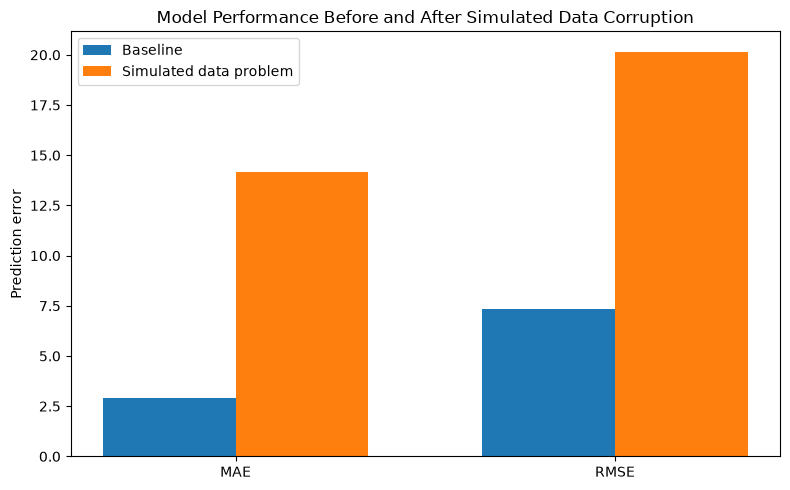

In [13]:
import matplotlib.pyplot as plt
from pathlib import Path

# Results from your completed ML experiment
baseline_mae = 2.9068
corrupted_mae = 14.1528

baseline_rmse = 7.3373
corrupted_rmse = 20.1635

metrics = ["MAE", "RMSE"]
baseline = [baseline_mae, baseline_rmse]
corrupted = [corrupted_mae, corrupted_rmse]

x = range(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    [i - width / 2 for i in x],
    baseline,
    width,
    label="Baseline"
)

ax.bar(
    [i + width / 2 for i in x],
    corrupted,
    width,
    label="Simulated data problem"
)

ax.set_ylabel("Prediction error")
ax.set_title("Model Performance Before and After Simulated Data Corruption")
ax.set_xticks(list(x))
ax.set_xticklabels(metrics)
ax.legend()

plt.tight_layout()

figures_dir = ROOT / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Results and Findings

## 1. Schema Evolution

The NYC TLC Yellow Taxi Trip Records for January 2024 and January 2025 were compared to identify changes in their schemas.

The January 2024 dataset contains 19 columns, while the January 2025 dataset contains 20 columns. The `cbd_congestion_fee` column was introduced in the 2025 dataset.

No columns were removed, and no changes were detected in the data types of shared columns.

This demonstrates how datasets can evolve over time as new business requirements introduce additional information.

## 2. Data Contract Validation

A data contract was created using the January 2024 schema as the baseline.

The contract specifies the required columns and their expected data types. It allows additional columns, so the new `cbd_congestion_fee` column does not invalidate the contract.

Both datasets passed validation because all required columns were present and their data types matched the contract.

This demonstrates how data contracts can help maintain compatibility when a dataset evolves.

## 3. Machine Learning Experiment

A machine learning regression model was trained using trip distance and passenger count to predict fare amount.

The baseline model achieved an MAE of approximately 2.9068 and an RMSE of approximately 7.3373.

A controlled experiment simulated a data-quality problem by replacing test-set trip-distance values with zero. The resulting MAE increased to approximately 14.1528, while the RMSE increased to approximately 20.1635.

These results demonstrate that corrupted input data can substantially degrade model performance.

The experiment does not establish that the actual schema change in January 2025 caused this degradation.

## 4. Conclusion

This project demonstrates three important concepts:

1. **Schema evolution:** Dataset structures can change over time as new columns are introduced.
2. **Data contracts:** Explicit rules for required columns and data types help detect incompatible changes.
3. **Machine learning reliability:** Data-quality problems can negatively affect model predictions.

Combining schema comparison, contract validation, and model evaluation provides a practical approach to understanding and managing changes in data pipelines.

## 5. Limitations

The schema comparison covers two monthly datasets. The machine learning experiment uses a sample of the January 2024 data and simulates a data-quality problem rather than measuring the impact of the actual schema change.

Further work could include testing breaking schema changes, enforcing contract validation directly in the model pipeline, and evaluating whether new columns improve model performance.

In [1]:
import json
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

with open(ROOT / "results" / "contract_enforced_ml_results.json", "r") as f:
    enforced_results = json.load(f)

enforced_summary = pd.DataFrame([{
    "Contract Status": enforced_results["contract_status"],
    "Dataset": enforced_results["dataset"],
    "Records Used": enforced_results["records_used"],
    "Features": ", ".join(enforced_results["features"]),
    "Target": enforced_results["target"],
    "MAE": enforced_results["mae"],
    "RMSE": enforced_results["rmse"]
}])

display(enforced_summary)

,Contract Status,Dataset,Records Used,Features,Target,MAE,RMSE
0,VALID,yellow_tripdata_2024-01.parquet,48302,"trip_distance, passenger_count",fare_amount,2.906836,7.337327


In [2]:
with open(ROOT / "results" / "ml_experiment.json", "r") as f:
    ml_results = json.load(f)

performance_comparison = pd.DataFrame([
    {
        "Experiment": "Baseline",
        "MAE": 2.9068,
        "RMSE": 7.3373
    },
    {
        "Experiment": "Simulated Data Corruption",
        "MAE": 14.1528,
        "RMSE": 20.1635
    }
])

display(performance_comparison)

,Experiment,MAE,RMSE
0,Baseline,2.9068,7.3373
1,Simulated Data Corruption,14.1528,20.1635


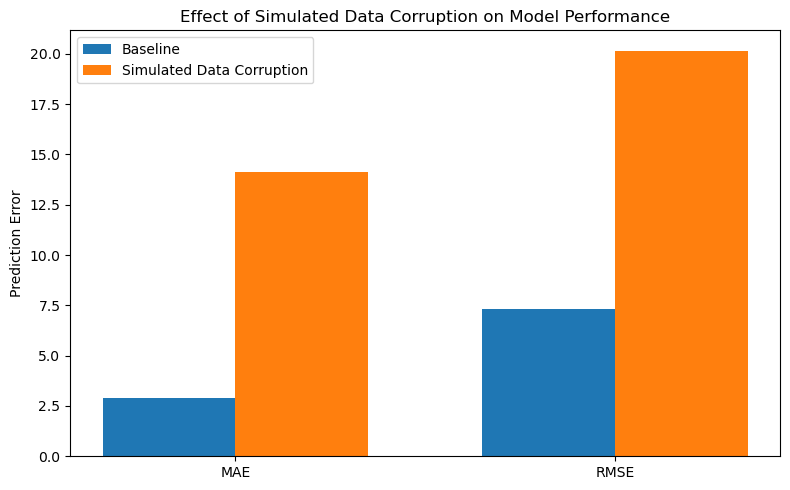

In [3]:
import matplotlib.pyplot as plt

metrics = ["MAE", "RMSE"]

baseline = [
    performance_comparison.loc[0, "MAE"],
    performance_comparison.loc[0, "RMSE"]
]

corrupted = [
    performance_comparison.loc[1, "MAE"],
    performance_comparison.loc[1, "RMSE"]
]

x = range(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    [i - width / 2 for i in x],
    baseline,
    width,
    label="Baseline"
)

ax.bar(
    [i + width / 2 for i in x],
    corrupted,
    width,
    label="Simulated Data Corruption"
)

ax.set_ylabel("Prediction Error")
ax.set_title("Effect of Simulated Data Corruption on Model Performance")
ax.set_xticks(list(x))
ax.set_xticklabels(metrics)
ax.legend()

plt.tight_layout()

figures_dir = ROOT / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "ml_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()